<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture provenance](README.md)

# 01 · A two-second container does not promise two seconds of video

A media inventory has several grains: one file, several streams, and individual metadata fields. We will compare container and stream durations, apply a local review threshold, and then probe the same bytes through a non-seekable pipe. The question is whether a missing or shorter measurement actually supports a claim about the content.

**Synthetic local media only.** The corpus contains a silent WAV, a one-second test-pattern MP4, a test-pattern MP4 with a longer tone track, and an invalid text file. A separate SQL NULL input tests absence. The real released Go worker runs the reader's `ffprobe`; no network media, camera, account or playback is used. These are controlled examples, not a survey of formats or a playback-quality test.

## Choose a duration-difference review threshold

`DURATION_GAP_SECONDS` is a finite number in **0–2 seconds**. Flag a stream when the **absolute difference** between its own reported duration and the container's reported duration is **strictly greater** than this threshold. The default is **0.1 seconds**; the experiment is **1.1 seconds**. This is a local screening rule, not a codec standard or a defect diagnosis.

Restart Kernel → Run All after editing. The media files and parsed measurements stay fixed; only the local screening decision changes.

In [1]:
DURATION_GAP_SECONDS = 0.1  # Seconds, strict > comparison; experiment: 1.1

In [2]:
import hashlib
import json
import math
import shutil
import subprocess
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(DURATION_GAP_SECONDS, (float, int)) and not isinstance(DURATION_GAP_SECONDS, bool)
assert math.isfinite(DURATION_GAP_SECONDS) and 0 <= DURATION_GAP_SECONDS <= 2
assert shutil.which("ffprobe"), "Install ffmpeg and put ffprobe on PATH; see README.md."
probe_version = subprocess.check_output(["ffprobe", "-version"], text=True).splitlines()[0]
manifest = json.loads(Path("fixtures/manifest.json").read_text())
for name, digest in manifest["files"].items():
    assert hashlib.sha256(Path("fixtures", name).read_bytes()).hexdigest() == digest
fingerprint = hashlib.sha256(json.dumps(manifest["files"], sort_keys=True).encode()).hexdigest()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Source: committed synthetic media · vgi-media v0.4.0 · local ffprobe · measurements, not playback validation",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-media/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-media/notebooks/pyproject.toml.

## Materialize the file inventory through the released worker

The literal `github-auto` location downloads and verifies the pinned platform release. It still requires **ffprobe on PATH**; this native dependency is reported below and is not pinned by the Python lockfile.

Each scalar probes its input separately. We materialize those bounded local calls once, then reuse ordinary tables for all comparisons and charts. `media_format` is a probe-success signal here; a NULL does not reveal whether the input was absent, rejected, timed out or lacked a field. A missing ffprobe executable is a configuration error that propagates instead of becoming NULL.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'media' (
 TYPE vgi,
 LOCATION 'github-auto://Query-farm/vgi-media@v0.4.0'
);
CREATE TABLE inputs(id,path) AS VALUES
 ('audio-tail.mp4','fixtures/audio-tail.mp4'),
 ('silent.wav','fixtures/silent.wav'),
 ('tiny.mp4','fixtures/tiny.mp4'),
 ('not-media.txt','fixtures/not-media.txt'),
 ('NULL input',NULL);
CREATE TABLE inventory AS
SELECT id,path,media.main.media_format(path) AS format,
 media.main.duration(path) AS container_seconds,
 media.main.media_size(path) AS reported_bytes,
 media.main.stream_count(path) AS reported_streams
FROM inputs;

,Count


In [4]:
%%sql files <<
SELECT id,format,container_seconds,reported_bytes,reported_streams
FROM inventory ORDER BY id;

In [5]:
display(files)
prose(
    f"**{files['format'].notna().sum()} of {len(files)} inputs** return a recognized format. The invalid text file and absent input remain in the inventory, rather than disappearing from the denominator. Native probe: `{probe_version}`. Fixture fingerprint: `{fingerprint}`."
)

,id,format,container_seconds,reported_bytes,reported_streams
0,NULL input,None,NaN,<NA>,<NA>
1,audio-tail.mp4,"mov,mp4,m4a,3gp,3g2,mj2",2.0,15264,2
2,not-media.txt,None,NaN,<NA>,<NA>
3,silent.wav,wav,1.0,16078,1
4,tiny.mp4,"mov,mp4,m4a,3gp,3g2,mj2",1.0,7429,1


**3 of 5 inputs** return a recognized format. The invalid text file and absent input remain in the inventory, rather than disappearing from the denominator. Native probe: `ffprobe version 9.0.2 Copyright (c) 2007-2026 the FFmpeg developers`. Fixture fingerprint: `791cca79d2bd3e6d35db204207b9b259b61e1c359d01b42f66c090613f324d52`.

## Keep stream rows at their own grain

A table function takes a constant path, so these explicit unions enumerate the small corpus. The invalid and NULL inputs produce no stream rows; the separate inventory preserves them. Video dimensions on an audio row are inapplicable, not zero-sized video.

`duration` is the stream's reported duration. Subtracting it from container duration gives a **length difference**, not an exact timeline gap: this schema does not expose stream start times. We cannot infer missing frames, silence, synchronization, or whether a player holds the final video frame.

In [6]:
%%sql
CREATE TABLE streams AS
SELECT 'audio-tail.mp4' AS id,* FROM media.main.media_streams('fixtures/audio-tail.mp4')
UNION ALL SELECT 'silent.wav',* FROM media.main.media_streams('fixtures/silent.wav')
UNION ALL SELECT 'tiny.mp4',* FROM media.main.media_streams('fixtures/tiny.mp4')
UNION ALL SELECT 'not-media.txt',* FROM media.main.media_streams('fixtures/not-media.txt')
UNION ALL SELECT 'NULL input',* FROM media.main.media_streams(NULL);
CREATE TABLE comparisons AS
SELECT s.id,s.idx,s.type,s.codec,s.duration AS stream_seconds,i.container_seconds,
 i.container_seconds-s.duration AS signed_difference_seconds,
 abs(i.container_seconds-s.duration)>{{DURATION_GAP_SECONDS}} AS needs_review
FROM streams s JOIN inventory i USING(id);

,Count


In [7]:
%%sql tracks <<
SELECT id,idx,type,codec,stream_seconds,container_seconds,
 signed_difference_seconds,needs_review FROM comparisons ORDER BY id,idx;

,id,idx,type,codec,stream_seconds,container_seconds,signed_difference_seconds,needs_review
0,audio-tail.mp4,0,video,h264,1.0,2.0,1.0,True
1,audio-tail.mp4,1,audio,aac,2.0,2.0,0.0,False
2,silent.wav,0,audio,pcm_s16le,1.0,1.0,0.0,False
3,tiny.mp4,0,video,h264,1.0,1.0,0.0,False


**4 stream rows** describe the recognized files. **1 of 4 comparable streams** exceed the strict **0.1 s** threshold; **0** lack one of the two durations and remain unevaluated. The largest absolute reported length difference is **1.000 s**. A flag asks for review; the intentionally longer tone track shows why it is not automatically corruption.

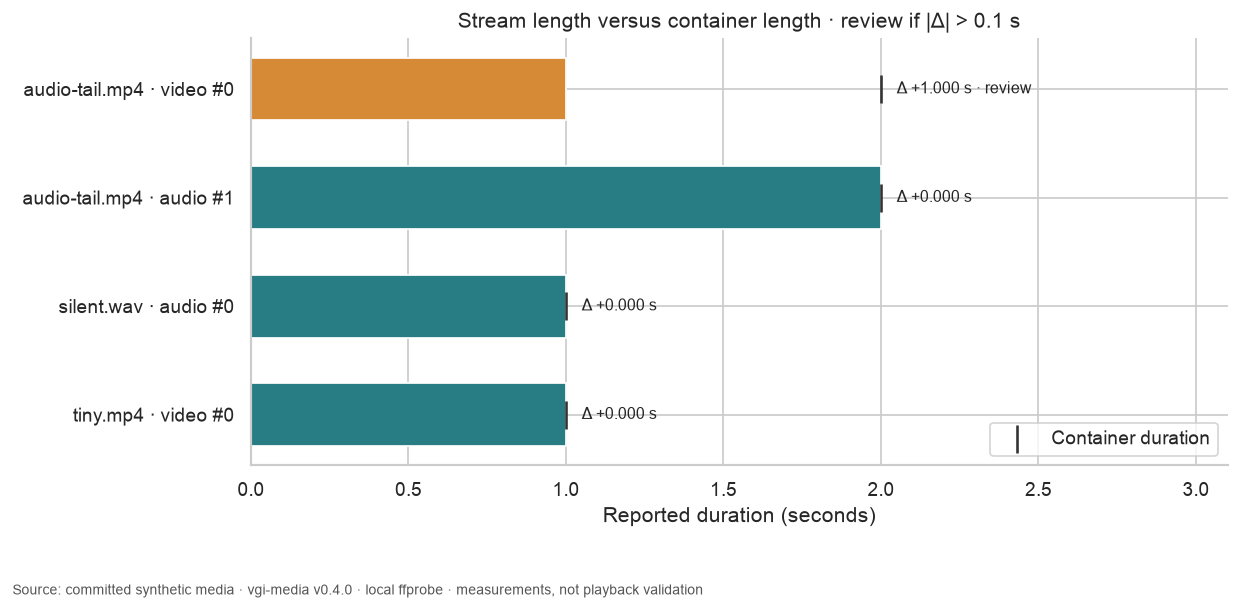

In [8]:
display(tracks)
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT id,idx FROM streams GROUP BY ALL HAVING count(*)<>1)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM inventory i LEFT JOIN (SELECT id,count(*) AS n FROM streams GROUP BY id) s USING(id) WHERE i.reported_streams IS NOT NULL AND i.reported_streams<>coalesce(s.n,0)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM streams WHERE type='audio' AND (width IS NOT NULL OR height IS NOT NULL)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM comparisons WHERE stream_seconds<0 OR container_seconds<0").fetchone()[
        0
    ]
    == 0
)
known = tracks.dropna(subset=["stream_seconds", "container_seconds"]).copy()
flagged = int(known.needs_review.sum())
prose(
    f"**{len(tracks)} stream rows** describe the recognized files. **{flagged} of {len(known)} comparable streams** exceed the strict **{DURATION_GAP_SECONDS:g} s** threshold; **{len(tracks) - len(known)}** lack one of the two durations and remain unevaluated. The largest absolute reported length difference is **{known.signed_difference_seconds.abs().max():.3f} s**. A flag asks for review; the intentionally longer tone track shows why it is not automatically corruption."
)
fig, ax = plt.subplots(figsize=(10, 5.2))
labels = [f"{r.id} · {r.type} #{r.idx}" for r in known.itertuples()]
y = list(range(len(known)))
ax.barh(
    y,
    known.stream_seconds,
    color=["#d68a36" if bool(v) else "#287d85" for v in known.needs_review],
    height=0.58,
)
ax.scatter(
    known.container_seconds, y, color="#333333", marker="|", s=270, label="Container duration", zorder=4
)
for i, r in enumerate(known.itertuples()):
    ax.text(
        max(r.stream_seconds, r.container_seconds) + 0.05,
        i,
        f"Δ {r.signed_difference_seconds:+.3f} s" + (" · review" if r.needs_review else ""),
        va="center",
        fontsize=9,
    )
ax.set(
    yticks=y,
    yticklabels=labels,
    xlabel="Reported duration (seconds)",
    title=f"Stream length versus container length · review if |Δ| > {DURATION_GAP_SECONDS:g} s",
)
ax.set_xlim(0, max(known.container_seconds.max(), known.stream_seconds.max()) * 1.55)
ax.invert_yaxis()
ax.legend(loc="lower right")
finish(fig)

## The same bytes can expose fewer fields through a pipe

Read the committed files into BLOBs and probe them through ffprobe's non-seekable standard input. Byte identity is unchanged, but the access method changes. `octet_length(content)` is a direct byte count; `media_size(content)` is a reported probe field and can be NULL.

The pinned **v0.4.0** release does not fill missing pipe sizes from BLOB length. Later repository source has that fallback, so source documentation can describe behavior absent from this release. We show both columns rather than silently repair the worker output. A NULL BLOB duration likewise does not mean zero seconds.

In [9]:
%%sql
CREATE TABLE blob_inputs AS
SELECT parse_filename(filename) AS id,content,octet_length(content) AS input_bytes
FROM read_blob('fixtures/*') WHERE parse_filename(filename)<>'manifest.json';
CREATE TABLE byte_probe AS
SELECT id,input_bytes,media.main.media_format(content) AS blob_format,
 media.main.duration(content) AS blob_seconds,
 media.main.media_size(content) AS blob_reported_bytes
FROM blob_inputs;
CREATE TABLE access_comparison AS
SELECT i.id,i.format AS path_format,b.blob_format,
 i.container_seconds AS path_seconds,b.blob_seconds,
 b.input_bytes,i.reported_bytes AS path_reported_bytes,b.blob_reported_bytes
FROM inventory i JOIN byte_probe b USING(id);

,Count


In [10]:
%%sql access <<
SELECT * FROM access_comparison ORDER BY id;

,id,path_format,blob_format,path_seconds,blob_seconds,input_bytes,path_reported_bytes,blob_reported_bytes
0,audio-tail.mp4,"mov,mp4,m4a,3gp,3g2,mj2","mov,mp4,m4a,3gp,3g2,mj2",2.0,2.0,15264,15264,<NA>
1,not-media.txt,None,None,NaN,NaN,31,<NA>,<NA>
2,silent.wav,wav,wav,1.0,NaN,16078,16078,<NA>
3,tiny.mp4,"mov,mp4,m4a,3gp,3g2,mj2","mov,mp4,m4a,3gp,3g2,mj2",1.0,1.0,7429,7429,<NA>


Among **3 recognized files**, **1** have a path duration but no BLOB duration. **3** have no BLOB-reported size even though their exact byte counts are known. That is metadata availability under this release and ffprobe version, not evidence of empty content. The invalid text input remains unrecognized by both access methods.

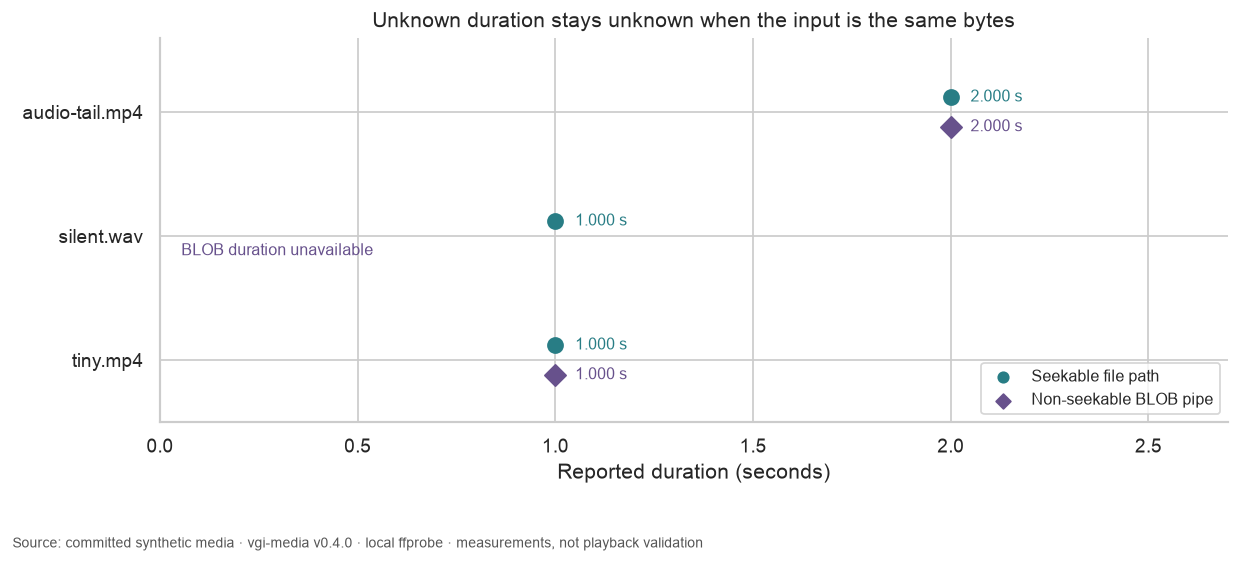

In [11]:
display(access)
assert (
    con.execute(
        "SELECT count(*) FROM access_comparison WHERE path_reported_bytes IS NOT NULL AND path_reported_bytes<>input_bytes"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM access_comparison WHERE blob_reported_bytes IS NOT NULL AND blob_reported_bytes<>input_bytes"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM inventory WHERE path IS NULL AND (format IS NOT NULL OR container_seconds IS NOT NULL OR reported_bytes IS NOT NULL OR reported_streams IS NOT NULL)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM comparisons WHERE needs_review IS DISTINCT FROM (abs(signed_difference_seconds)>?)",
        [DURATION_GAP_SECONDS],
    ).fetchone()[0]
    == 0
)
measured = access[access.path_format.notna()].copy()
lost = int((measured.path_seconds.notna() & measured.blob_seconds.isna()).sum())
unknown_sizes = int(measured.blob_reported_bytes.isna().sum())
prose(
    f"Among **{len(measured)} recognized files**, **{lost}** have a path duration but no BLOB duration. **{unknown_sizes}** have no BLOB-reported size even though their exact byte counts are known. That is metadata availability under this release and ffprobe version, not evidence of empty content. The invalid text input remains unrecognized by both access methods."
)
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, r in enumerate(measured.itertuples()):
    for offset, value, color, marker in [
        (-0.12, r.path_seconds, "#287d85", "o"),
        (0.12, r.blob_seconds, "#67518c", "D"),
    ]:
        if pd.notna(value):
            ax.scatter(value, i + offset, color=color, marker=marker, s=75)
            ax.text(value + 0.05, i + offset, f"{value:.3f} s", va="center", fontsize=9, color=color)
        else:
            ax.text(
                0.02,
                i + offset,
                "BLOB duration unavailable",
                transform=ax.get_yaxis_transform(),
                va="center",
                fontsize=9,
                color=color,
            )
ax.scatter([], [], color="#287d85", marker="o", label="Seekable file path")
ax.scatter([], [], color="#67518c", marker="D", label="Non-seekable BLOB pipe")
ax.set(
    yticks=list(range(len(measured))),
    yticklabels=measured.id,
    xlabel="Reported duration (seconds)",
    title="Unknown duration stays unknown when the input is the same bytes",
)
ax.set_xlim(0, float(measured.path_seconds.max()) * 1.35)
ax.set_ylim(len(measured) - 0.5, -0.6)
ax.legend(loc="lower right", fontsize=9)
finish(fig)

## Experiment: relax only the review threshold

Change `DURATION_GAP_SECONDS` from **0.1 to 1.1** in a separate execution. Predict that fewer streams are flagged. Compare the flagged count and orange bars, while checking that the duration values, file fingerprint, byte counts and path-versus-BLOB availability remain unchanged.

Restore **0.1** afterwards. A looser threshold changes a screening policy; it neither repairs media nor proves playback quality. For real investigations, obtain start times and perform a decode/playback check before interpreting a duration difference as a timeline defect.

In [12]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)